Given  X is a uniform, continuous distribution on (-1,1), and Y = $X^2$, we can find their covarience.

Covarience is defined as $$Cov(X,Y) = E{(X-\mu_x)(Y-\mu_Y)}$$

However, an easier way of writing this formula would be $$Cov(X,Y) = E(X,Y) - E(X)E(Y)$$, which I derive below from the original form.  

This is found from cross multiplying the original formula and taking $E({\mu}_X)$ or $E({\mu}_Y)$ to equal ${\mu}_X$ and ${\mu}_Y$, respectively, as the expected value of the mean is itself.  In addition, $E({\mu}_X{\mu}_Y)$ would be equal to ${\mu}_X {\mu}_Y$ by the same principle.  From there, when we distribute $(X-\mu_x)(Y-\mu_Y)$ within $E()$, we get $E(XY-\mu_YX-\mu_xY+\mu_x\mu_y)$.  Taking the varience of each of these terms $E(XY) - E(\mu_YX) - E(\mu_xY) - E(\mu_x\mu_y)$.  From our earlier statements, we can move the $\mu_X$ and $\mu_y$ terms outside the funcion E() in the terms $E(\mu_YX)$ and $E(\mu_xY)$ and write this as  $E(XY) - \mu_X\mu_Y - \mu_X\mu_Y + \mu_X\mu_Y$.  Cancelling the two identical terms, we get our final form $$Cov(X,Y) = E(X,Y) - E(X)E(Y)$$.

So, to solve for the covarience, we find the expected value of E(X), then $E(Y) = E(X^2)$.  Finding E(XY) is the same as $E(X*X^2)$ or $E(X^3)$.

We take the expected value of a continuous function g(x) to be $E[g(X)] = \int_{a}^{b} g(x)f_X(x) \,dx$, with $f_X(x)$ being the probability density over the interval [a,b].  For the uniform distribution -1, 1, we find $f_X(x)$ to be $\frac{1}{2}$.

Therefore, E(X) would be $$E[X] = \int_{-1}^{1} \frac{1}{2}X \,dx = 0$$

Then, E(Y) would be $$E[Y] = E[X^2]  = \int_{-1}^{1} \frac{1}{2}X^2 \,dx = \frac{1}{3}$$

Finally, E(XY) would be $$E[XY] = E[X^3]  = \int_{-1}^{1} \frac{1}{2}X^3 \,dx = 0$$.

We can see the final result of  $$Cov(X,Y) = E(X,Y) - E(X)E(Y)$$ is zero, as  $$Cov(X,Y) = 0 - 0*\frac{1}{3} = 0$$



Next, we verify this with 10^7 samples that the correlation is zero with its error:

In [22]:
import numpy as np

rng = np.random.default_rng(42) #change me later!!!!!!!!!!!!!!!!!!!
n=10**7
X = rng.uniform(-1,1,n)
Y = X**2

r = np.corrcoef(X,Y)[0,1] #grab row 0, col 1 of matrix which is COR(X,Y)
print("Sample Correlation:", r)
stan_er = np.sqrt((1-r**2) / (n-2))
print(f"Standard Error: {stan_er:.5f}")

Sample Correlation: 0.0003102502059538182
Standard Error: 0.00032


We can see that the correlation is slightly positive.  However, the estimate is within one standard error of zero, which means X and Y do not show much correlation even though they are very much dependant.

We can show they are dependant by plotting the scatter with many pairs of X and Y.  If we can show every X value results in a predictable, repeatable, deterministic Y value every time, we prove Y is completely dependant on X.  We can do this by showing the variance of results is zero, which shows each result is determinitic.  We must use bins, however, as exact values would not be repeated more than once in a continuous distribution, making us use a range of values in bins to prove our point.

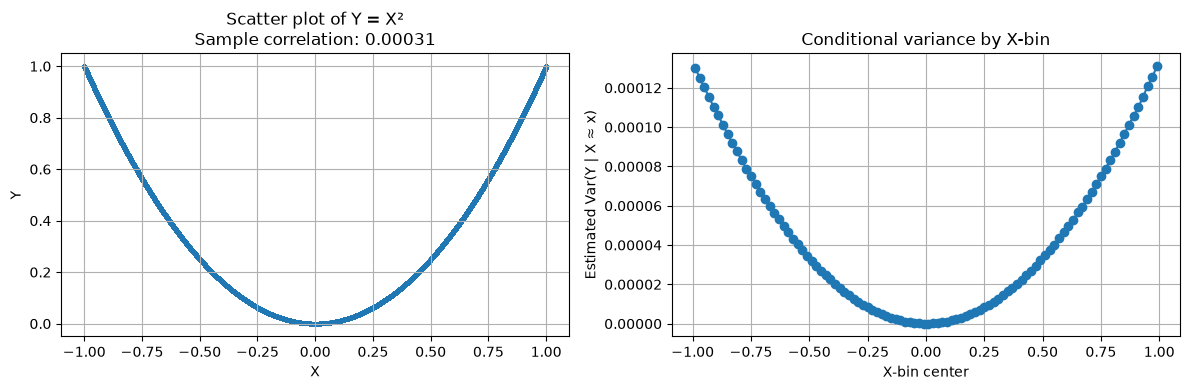

Largest estimated conditional variance with Sample Correlation: 0.0003102502059538182 is 0.0001310014469850826


In [23]:
import matplotlib.pyplot as plt

#use prior Samples of x

#bins: 100 of them
bin_edges = np.linspace(-1,1,101)
bin_centers = (bin_edges[:-1]+bin_edges[1:])/2
conditional_variances = []

#calculate variance of Y within x bin
for left, right in zip(bin_edges[:-1], bin_edges[1:]):
    in_bin = (X >= left) & (X < right)
    Y_in_bin = Y[in_bin]

    variance = np.var(Y_in_bin, ddof = 1)
    conditional_variances.append(variance)

conditional_variances = np.array(conditional_variances)

#2 plots
fig, axes = plt.subplots(1,2,figsize=(12,4))

#scatter plot
axes[0].scatter(X,Y, s=2, alpha=0.2)
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_title(
    f"Scatter plot of Y = X²\nSample correlation: {r:.5f}"
)
axes[0].grid(True)

# Est con var
axes[1].plot(bin_centers, conditional_variances, "o-")
axes[1].set_xlabel("X-bin center")
axes[1].set_ylabel("Estimated Var(Y | X ≈ x)")
axes[1].set_title("Conditional variance by X-bin")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Largest estimated conditional variance with Sample Correlation:", r, "is", 
      np.max(conditional_variances))

We can see the conditional variance for each bin is centered exactly on the curve of the scatter plot.  Because variance lies directly on the curve and is miniscule, we can see the relation is deterministic, with every x value corresponding to only one y value. 

Sample correlation:              0.00010
RMSE:                             0.00023
Mean absolute difference:         0.00012
Maximum absolute difference:      0.00156
Total absolute difference:        0.00748


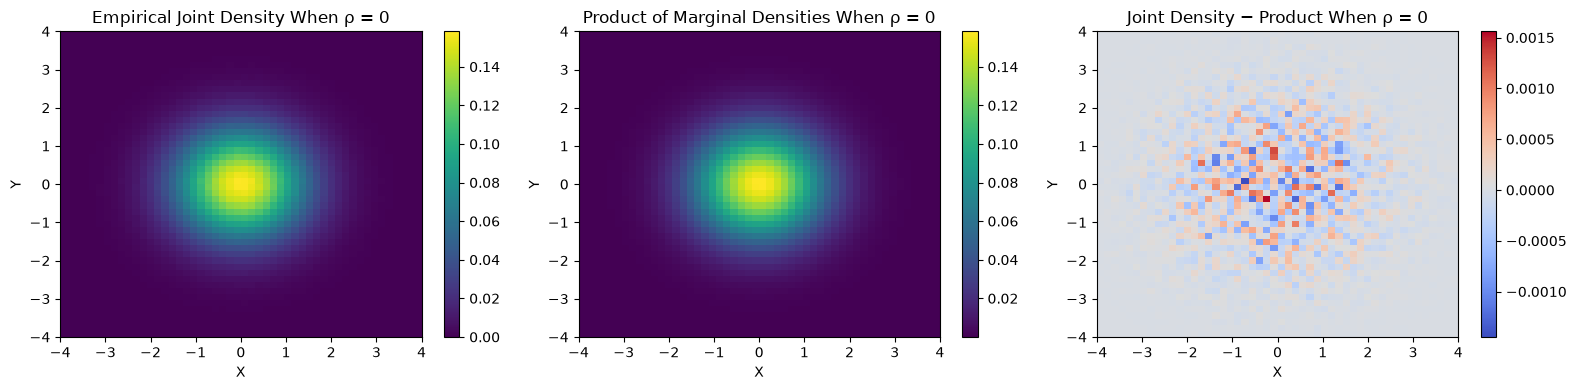

In [26]:
import numpy as np
import matplotlib.pyplot as plt


rho = 0.0

# Covariance matrix for two standard normal variables
covariance_matrix = np.array([
    [1.0,  rho],
    [rho, 1.0]
])

samples = rng.multivariate_normal(
    mean=[0, 0],
    cov=covariance_matrix,
    size=n
)

X = samples[:, 0]
Y = samples[:, 1]

#joint density

number_of_bins = 50
bin_edges = np.linspace(-4, 4, number_of_bins + 1)

joint_density, x_edges, y_edges = np.histogram2d(
    X,
    Y,
    bins=[bin_edges, bin_edges],
    density=True
)

#marginal density on their own

density_X, _ = np.histogram(
    X,
    bins=bin_edges,
    density=True
)

density_Y, _ = np.histogram(
    Y,
    bins=bin_edges,
    density=True
)
#mult.  the marginals together

product_of_marginals = np.outer(density_X, density_Y)

#compare the multipled marginals vs actual

difference = joint_density - product_of_marginals

bin_width = bin_edges[1] - bin_edges[0]

rmse = np.sqrt(np.mean(difference**2))
mean_absolute_difference = np.mean(np.abs(difference))
max_absolute_difference = np.max(np.abs(difference))

# Approximate total abs diff across density surface
total_absolute_difference = (
    np.sum(np.abs(difference)) * bin_width**2
)

sample_correlation = np.corrcoef(X, Y)[0, 1]

print(f"Sample correlation:              {sample_correlation:.5f}")
print(f"RMSE:                             {rmse:.5f}")
print(f"Mean absolute difference:         {mean_absolute_difference:.5f}")
print(f"Maximum absolute difference:      {max_absolute_difference:.5f}")
print(f"Total absolute difference:        {total_absolute_difference:.5f}")

# Plot


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Directly estimated joint density
plot_1 = axes[0].pcolormesh(
    x_edges,
    y_edges,
    joint_density.T,
    shading="auto"
)
axes[0].set_title("Empirical Joint Density When ρ = 0")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
fig.colorbar(plot_1, ax=axes[0])

# Product of marginal densities
plot_2 = axes[1].pcolormesh(
    bin_edges,
    bin_edges,
    product_of_marginals.T,
    shading="auto"
)
axes[1].set_title("Product of Marginal Densities When ρ = 0")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
fig.colorbar(plot_2, ax=axes[1])

# Difference
plot_3 = axes[2].pcolormesh(
    bin_edges,
    bin_edges,
    difference.T,
    shading="auto",
    cmap="coolwarm"
)
axes[2].set_title("Joint Density − Product When ρ = 0")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Y")
fig.colorbar(plot_3, ax=axes[2])

plt.tight_layout()
plt.show()

We can see the Empirical joint density and the product of the marginal densities are closely matched with a root mean square error of 0.00024 between the differences of the two.  This strongly supports the independence of the Gaussian pair as an independent relation would show $$f_{X,Y}(x,y) = f_X(x)f_Y(y)$$ which means the marginal probability multiplied together should be identical to the probability of the joint density.
 
 Because of this, we can see for Gaussian pairs, the depedance is related to the correlation between the pair, unlike our last example. We can say:  $$\text{The jointly Gaussian pair is independant iff the correlation is zero}$$.

 We can also say $$\text{The jointly Gaussian pair is dependant iff the correlation is nonzero}$$
 which I will support with an extra example of this below.

Sample correlation:              0.89999
RMSE:                             0.03584
Mean absolute difference:         0.01597
Maximum absolute difference:      0.20212
Total absolute difference:        1.02186


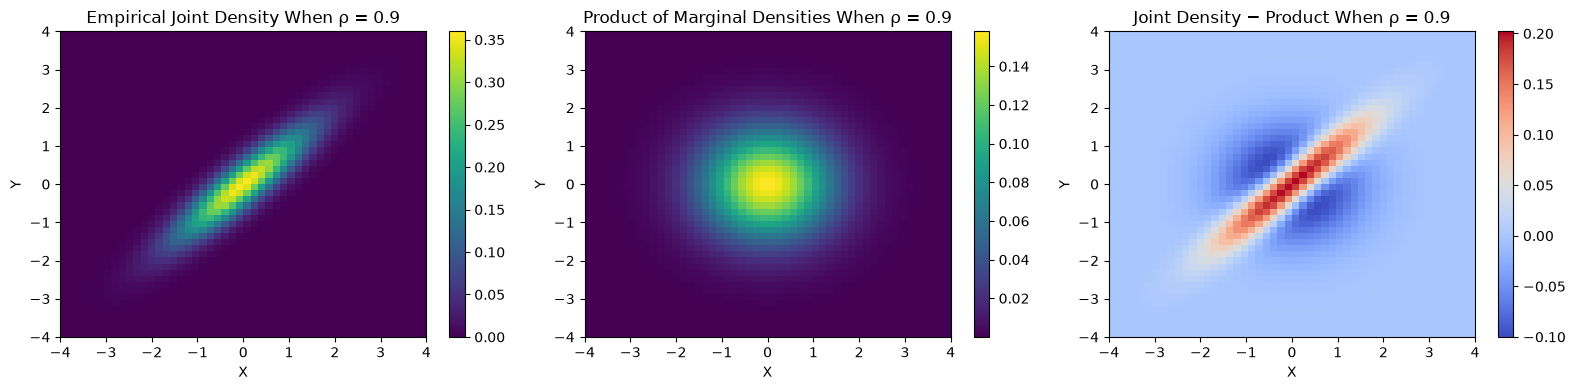

In [27]:
import numpy as np
import matplotlib.pyplot as plt


rho = 0.9

# Covariance matrix for two standard normal variables
covariance_matrix = np.array([
    [1.0,  rho],
    [rho, 1.0]
])

samples = rng.multivariate_normal(
    mean=[0, 0],
    cov=covariance_matrix,
    size=n
)

X = samples[:, 0]
Y = samples[:, 1]

#joint density

number_of_bins = 50
bin_edges = np.linspace(-4, 4, number_of_bins + 1)

joint_density, x_edges, y_edges = np.histogram2d(
    X,
    Y,
    bins=[bin_edges, bin_edges],
    density=True
)

#marginal density on their own

density_X, _ = np.histogram(
    X,
    bins=bin_edges,
    density=True
)

density_Y, _ = np.histogram(
    Y,
    bins=bin_edges,
    density=True
)
#mult.  the marginals together

product_of_marginals = np.outer(density_X, density_Y)

#compare the multipled marginals vs actual

difference = joint_density - product_of_marginals

bin_width = bin_edges[1] - bin_edges[0]

rmse = np.sqrt(np.mean(difference**2))
mean_absolute_difference = np.mean(np.abs(difference))
max_absolute_difference = np.max(np.abs(difference))

# Approximate total abs diff across density surface
total_absolute_difference = (
    np.sum(np.abs(difference)) * bin_width**2
)

sample_correlation = np.corrcoef(X, Y)[0, 1]

print(f"Sample correlation:              {sample_correlation:.5f}")
print(f"RMSE:                             {rmse:.5f}")
print(f"Mean absolute difference:         {mean_absolute_difference:.5f}")
print(f"Maximum absolute difference:      {max_absolute_difference:.5f}")
print(f"Total absolute difference:        {total_absolute_difference:.5f}")

# Plot


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Directly estimated joint density
plot_1 = axes[0].pcolormesh(
    x_edges,
    y_edges,
    joint_density.T,
    shading="auto"
)
axes[0].set_title("Empirical Joint Density When ρ = 0.9")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
fig.colorbar(plot_1, ax=axes[0])

# Product of marginal densities
plot_2 = axes[1].pcolormesh(
    bin_edges,
    bin_edges,
    product_of_marginals.T,
    shading="auto"
)
axes[1].set_title("Product of Marginal Densities When ρ = 0.9")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
fig.colorbar(plot_2, ax=axes[1])

# Difference
plot_3 = axes[2].pcolormesh(
    bin_edges,
    bin_edges,
    difference.T,
    shading="auto",
    cmap="coolwarm"
)
axes[2].set_title("Joint Density − Product When ρ = 0.9")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Y")
fig.colorbar(plot_3, ax=axes[2])

plt.tight_layout()
plt.show()

Simply changing the correlation to be 0.9 from 0, we can see how the product of marginal densities and the empirical joint density are not matching.  From here, we see an example of the earlier statement that $$\text{The jointly Gaussian pair is dependant iff the correlation is nonzero}$$  When we make the correlation nonzero (0.9), we see the RSME becomes 197% larger, indicating a major change in how similar the two are.

 Why would the Gaussian pair's dependance related to correlation when the other dependant relation we looked at was not?  This is because the correlation works on linear relationships.  For the nonlinear relation $Y = X^2$, the variables might be dependant but are not linear.  The Gaussian cloud has a linear tendency because the conditional average is linear, with variables scattering around that average. For the Gaussian pair, $$Cov(X,Y) = \rho \sigma_X \sigma_Y$$  By setting $\rho$ to greater than zero, we see the cloud tilts upward.  When $\rho$ is set to less than zero, we see the cloud tilts down.  When $\rho$ is zero, we see the cloud has no tilt.

 This property makes jointly Gaussian vectors very important in an engineering context, as correlation between them signals dependance.  We can tell if two signals are independant by simply finding their covariance, telling us if there is common noise between them or if the error between the sensors is independant.